# Plot CDR fluxes and the national trajectory

CDR is **exported alkalinity only** (`cdr_export`). E0 is B25 as published; E2 keeps B25's pH and soil CO2 and solves for the carbonate alkalinity the drainage can carry. `CASE` picks the scenario (1Gt or 2Gt).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, re
import numpy as np, xarray as xr, matplotlib as mpl, matplotlib.pyplot as plt
import fsspec, pandas as pd
import cmocean
from scipy.stats import gaussian_kde

CASE     = "1gt"                                        # "1gt" or "2gt"
TAG      = {"1gt": "e0-conus-1gt", "2gt": "e0-conus-2gt"}[CASE]
ROOT     = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/{TAG}")

# ---- design, shared by every fx-* figure notebook -------------------
THEME = "haline"        # "balance" | "haline" | "dense"
cm = cmocean.cm
THEMES = dict(                        #  E0            /    other
    balance=(cm.balance(.18), cm.balance(.82), cm.balance(.82)),   # blue / red
    haline =(cm.haline(.35),  cm.solar(.55), cm.solar(.55)),       # teal / brick
    dense  =(cm.dense(.50),   cm.solar(.60), cm.solar(.60))        # violet / gold
)
C = dict(zip(("e0", "e1", "e2"), THEMES[THEME]))
C.update(published="0.35", ctrl="0.60", ink="0.15", muted="0.45")
C["req"] = C["e1"]
W = dict(col1=3.42, col15=4.49, col2=7.05)   # in: PNAS 1 / 1.5 / 2-column

mpl.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 600, "figure.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42,       # TrueType; journals reject Type 3
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "text.color": C["ink"], "axes.labelcolor": C["ink"],
    "axes.labelsize": 10.5, "axes.titlesize": 10.5, "axes.titleweight": "regular",
    "axes.titlelocation": "left", "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5, "axes.linewidth": 0.9, "axes.edgecolor": "0.25",
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "0.25", "ytick.color": "0.25",
    "xtick.labelcolor": C["ink"], "ytick.labelcolor": C["ink"],
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 3.6, "ytick.major.size": 3.6,
    "xtick.minor.width": 0.7, "ytick.minor.width": 0.7,
    "xtick.minor.size": 2.0, "ytick.minor.size": 2.0,
    "legend.frameon": False, "legend.handlelength": 1.3, "legend.borderpad": 0.0,
    "legend.handletextpad": 0.55, "legend.labelspacing": 0.40, "lines.linewidth": 1.8,
})

def density(ax, x, w, color, label=None, *, lo, hi, log=True, n=400, fill=.22,
            ls="-", z=3):
    """Area-weighted KDE, light fill under a line (`fill=0` + dashed `ls`: unfilled reference)."""
    t = np.log10 if log else (lambda v: v)
    d = gaussian_kde(t(x), weights=w)(g := np.linspace(t(lo), t(hi), n))
    xs = 10 ** g if log else g
    ax.fill_between(xs, 0, d, color=color, alpha=fill, lw=0, zorder=z)
    ax.plot(xs, d, color=color, lw=1.8, ls=ls, zorder=z + 1, label=label)

def save(fig, stem):
    """PNG (600 dpi) and PDF into panels/."""
    os.makedirs("panels", exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"panels/{stem}.{ext}", bbox_inches="tight", pad_inches=.02)

# ---- the deployed point-years, each carrying its hectares --------------------
pt   = xr.open_zarr(f"{POSTPROC}/point.zarr").load()
SCEN = int(str(pt.attrs["scenario"]).lstrip("S"))
ACT  = pt.time >= pt.start_year + 3        # a point-year counts once rock is applied
AREA = (pt.area_ha * xr.ones_like(pt.time, dtype=float)).where(ACT)

def flat(v, positive=False):
    """Deployed point-years of `v`, paired with their hectares. NaNs dropped."""
    x, w = pt[v].where(ACT).values.ravel(), AREA.values.ravel()
    m = np.isfinite(x) & np.isfinite(w)
    if positive:
        m &= x > 0
    return x[m], w[m]

def wq(x, w, p):
    """Weighted quantile, linear interpolation on the midpoint CDF."""
    o = np.argsort(x); x, w = x[o], w[o]
    return np.interp(p, (np.cumsum(w) - .5 * w) / w.sum(), x)

print(f"{TAG}  S{SCEN}  {pt.sizes['point']:,} points  "
      f"{float(pt.area_ha.sum()) / 1e6:.2f} M ha  {int(pt.time[0])}-{int(pt.time[-1])}")

e0-conus-1gt  S1  2,322 points  24.49 M ha  2020-2070


## Main text — B25 CDR vs other scale estimates (`fig-scale-est`)

B25 peak year 2067: CDR-weighted 8.70, highest point 14.52 t CO2/ha/yr; points p5 4.17  p25 6.19  p75 9.43  p95 12.70


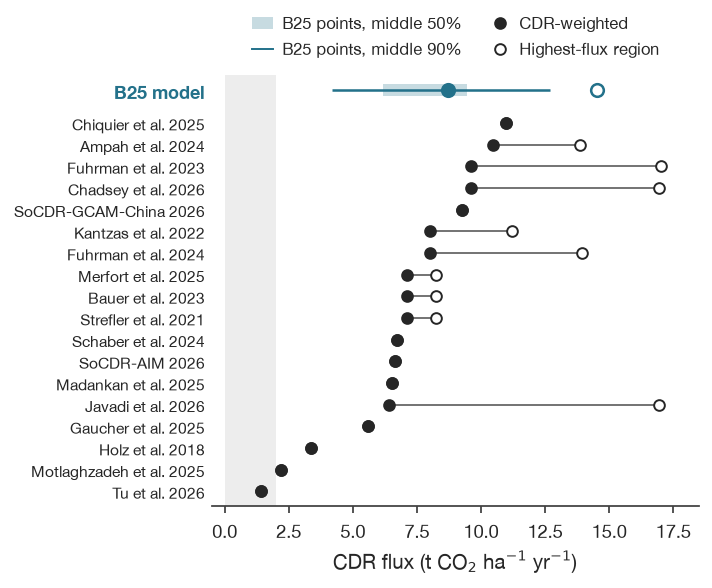

In [2]:
BASE = "cdr_export"   # exported alkalinity only, cumulative t CO2/ha

# IAM reference fluxes (t CO2/ha/yr): the peak-flux table from
# iam-rtm-compare/process/synthesis/erw_iam_scenarios.ipynb, one row per reference
IAM_TABLE = "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/_iam-synthesis/erw_peak_flux_table.md"
IAM_GROUPS = ("iams", "socdr", "other")   # any of "iams", "socdr", "other"
SOCDR_RUNS = "max_erw"          # "all", or "max_erw": the global and national SoCDR IAM with the most ERW CDR
IAM_METRIC = "cdr_weighted"     # or "highest_region"
IAM_EXCLUDE = ("Beerling et al. (2025)",)      # B25 itself, shown from this run


def peak_flux_table(path):
    """The table's rows, with total CDR and the two fluxes as numbers."""
    with fsspec.open(path, "r") as f:
        rows = [[c.strip() for c in l.strip().strip("|").split("|")] for l in f if l.startswith("|")]
    num = {"Total ERW CDR (Gt CO2/yr)": "gt", "CDR-weighted flux (t CO2/ha/yr)": "cdr_weighted",
           "Highest-region flux (t CO2/ha/yr)": "highest_region"}
    return pd.DataFrame(rows[2:], columns=rows[0]).rename(columns=num).astype(dict.fromkeys(num.values(), float))


tab = peak_flux_table(IAM_TABLE)
assert set(IAM_GROUPS) <= set(tab["Group"]) and SOCDR_RUNS in ("all", "max_erw"), (IAM_GROUPS, SOCDR_RUNS)
soc = tab["Group"] == "socdr"
best = tab[soc].groupby("Scope")["gt"].idxmax()     # per scope, the SoCDR IAM with the most ERW CDR
tab = tab[tab["Group"].isin(IAM_GROUPS) & ~tab["Reference"].isin(IAM_EXCLUDE)
          & (~soc | (SOCDR_RUNS == "all") | tab.index.isin(best))]
IAM = {re.sub(r" \((\d{4})\)$", r" \1", r["Reference"]):      # "Fuhrman et al. 2023"
       dict(cdr_weighted=r["cdr_weighted"], highest_region=r["highest_region"], group=r["Group"], model=r["Model"],
            citation=f"{r['Reference']}, {r['Model']}",
            note=f"{r['Scenario']}, peak {r['Peak year']}; {r['Area basis']}"
                 + (f"; top {r['Highest region']}" if r["highest_region"] > r["cdr_weighted"] else "")
                 + ("; still rising" if r["Still rising at end of run"] == "yes" else ""))
       for _, r in tab.iterrows()}
assert IAM, "IAM_GROUPS selects no references"
for m in IAM.values():
    m["value"] = m[IAM_METRIC]

def flux(v):
    """Deployed point-years of the annual per-hectare flux (year-on-year increment), with their hectares."""
    c = pt[v].fillna(0.)
    x = (c - c.shift(time=1, fill_value=0.)).where(ACT).values.ravel()
    w = AREA.values.ravel()
    m = np.isfinite(x) & np.isfinite(w)
    return x[m], w[m]

fx0, wf0 = flux(BASE)
m0 = wq(fx0, wf0, .5)
LO, HI = -0.5, 18.5
ORDER = sorted(IAM, key=lambda k: IAM[k]["cdr_weighted"])     # bottom to top
XMAX = HI                   # flux axis limit; raise to ~33 to fit every IAM mark

def inner(ax, x, w, m, color, label, log=True, dx=0):
    """Median as a solid line inside the distribution, `label` above the local peak."""
    t = np.log10 if log else (lambda v: v)
    k = gaussian_kde(t(x), weights=w)
    ax.vlines(m, 0, k(t(m))[0], color=color, lw=1.1, zorder=6)
    top = k(np.linspace(t(m) - .3, t(m) + .3, 61)).max()
    ax.annotate(label, xy=(m, top), xytext=(dx, 4), textcoords="offset points",
                color=color, ha="center", va="bottom", linespacing=1.15, zorder=7)


def iam_row(ax, k, y, xmax=XMAX, ms=5.5, shape="o"):
    """CDR-weighted (filled) and highest region (hollow), joined; values past `xmax` become an edge arrow."""
    a, b = IAM[k]["cdr_weighted"], IAM[k]["highest_region"]
    if b > a:
        ax.hlines(y, min(a, xmax), min(b, xmax), color=C["muted"], lw=1.0, zorder=2)
    for v, face in ((b, "white"), (a, C["ink"])):
        if v <= xmax:
            ax.plot(v, y, shape, ms=ms, mfc=face, mec=C["ink"], mew=1.0, zorder=3)
    over = sorted({v for v in (a, b) if v > xmax})       # one value when a == b
    if over:
        ax.plot(xmax, y, ">", ms=ms, mfc=C["ink"] if a > xmax else "white", mec=C["ink"], mew=1.0,
                zorder=3, clip_on=False)
        ax.annotate("–".join(f"{v:.0f}" for v in over), xy=(xmax, y), xytext=(7, 0),
                    textcoords="offset points", va="center", fontsize=8, color=C["muted"],
                    annotation_clip=False)


# B25 in its peak year, summarised like the IAM table (its points as the regions)
c = pt[BASE].fillna(0.)
f = c - c.shift(time=1, fill_value=0.)
PEAK = int(f.time[int((f * pt.area_ha).sum("point").argmax())])
fp = f.sel(time=PEAK).values
ap = pt.area_ha.values[fp > 0]
fp = fp[fp > 0]
cw = (fp * fp * ap).sum() / (fp * ap).sum()
p05, p25, p75, p95 = (wq(fp, ap, p) for p in (.05, .25, .75, .95))
print(f"B25 peak year {PEAK}: CDR-weighted {cw:.2f}, highest point {fp.max():.2f} t CO2/ha/yr; "
      f"points p5 {p05:.2f}  p25 {p25:.2f}  p75 {p75:.2f}  p95 {p95:.2f}")

yb = len(ORDER) + .5                            # B25 on top, half a row clear of the IAM rows
LIME_CDR = (.01, 2.0)       # t CO2/ha/yr, CDR from cation release under steady-state liming
fig, ax = plt.subplots(figsize=(W["col15"], 4.0))
ax.axvspan(*LIME_CDR, color=C["ink"], alpha=.08, lw=0, zorder=0)
ax.hlines(yb, p05, p95, color=C["e0"], lw=1.3, zorder=2)
ax.add_patch(mpl.patches.Rectangle((p25, yb - .28), p75 - p25, .56, color=C["e0"], alpha=.25, lw=0, zorder=2))
for v, face in ((fp.max(), "white"), (cw, C["e0"])):
    ax.plot(v, yb, "o", ms=6.5, mfc=face, mec=C["e0"], mew=1.3, zorder=3)
for i, k in enumerate(ORDER):
    iam_row(ax, k, i)
ax.set_yticks([*range(len(ORDER)), yb], [*ORDER, "B25 model"], fontsize=8)
ax.get_yticklabels()[-1].set(color=C["e0"], fontweight="bold", fontsize=9)
ax.set_xlim(LO, XMAX)
ax.set_ylim(-.7, yb + .7)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("CDR flux (t CO$_2$ ha$^{-1}$ yr$^{-1}$)")
spread = [mpl.patches.Patch(color=C["e0"], alpha=.25, lw=0, label="B25 points, middle 50%"),
          mpl.lines.Line2D([], [], color=C["e0"], lw=1.0, label="B25 points, middle 90%")]
metric = [mpl.lines.Line2D([], [], ls="", marker="o", ms=5.5, mfc=f, mec=C["ink"], label=n)
          for f, n in ((C["ink"], "CDR-weighted"), ("white", "Highest-flux region"))]
ax.legend(handles=spread + metric, ncol=2, loc="lower center", bbox_to_anchor=(.5, 1.02), fontsize=8.5,
          columnspacing=1.6)
save(fig, "cdr-iam-rows-export_" + CASE)

## Main text — CDR flux vs pH, and the U.S. total (`fig-cdr`)

- **a:** B25's point-years (each cloud its densest 90%) over carbonate-system curves for the dry / median / wet conditions in `Q_SET`, `CO2_SET` and `PH_CTRL`. The band is B25's middle 90% in q × soil CO2. Side panel: flux distributions and EW scale estimates (points).
- **b:** U.S. CDR over time.
- E2 runs ~1.5× above its annual-mean curve due to Jensen's inequality. (E2 is computed at every timestep then turned into a cumulative, annual sum, which exceeds the annual mean becasue the alk vs pH function is convex.)

In [3]:
YRS = pt.time.values

def national(v):
    """Per-hectare cumulative t CO2/ha -> national annual rate, Gt CO2/yr. Area first, then difference,
    then sum, since points start in different years."""
    c = (pt[v] * pt.area_ha).fillna(0.)
    return ((c - c.shift(time=1, fill_value=0.)).sum("point") / 1e9).values

# CaCO3-equivalent: cdr_export = eta x charge and CaCO3 carries 2 eq (eta varies <1% over CONUS)
ETA  = wq(pt.eta.values, pt.area_ha.values, .5)
LIME = 100.087 / (2 * ETA * 44.009)               # t CaCO3 per t CO2

fx2, wf2 = flux(BASE + "_e2")
sx0, ws0 = flux("cdr")                            # export + soil carbonate (SIC)
sx2, ws2 = flux("cdr_e2")
m2       = wq(fx2, wf2, .5)                       # export
s0, s2   = wq(sx0, ws0, .5), wq(sx2, ws2, .5)     # export + SIC
r0, r2   = national(BASE), national(BASE + "_e2")
c0 = ((pt[BASE] * pt.area_ha).fillna(0.).sum("point") / 1e9).values
c2 = ((pt[BASE + "_e2"] * pt.area_ha).fillna(0.).sum("point") / 1e9).values

print(f"eta {ETA:.4f}  ->  1 t CO2 = {LIME:.3f} t CaCO3-equivalent")
print(f"CDR flux, t CO2/ha/yr  median      p5     p10     p90     p95   median as CaCO3-eq")
for k, x, w in (("E0  export      ", fx0, wf0), ("E0  export + SIC", sx0, ws0),
                ("E2  export      ", fx2, wf2), ("E2  export + SIC", sx2, ws2)):
    m = wq(x, w, .5)
    print(f"  {k}{m:11.2f}" + "".join(f"{wq(x, w, q):8.2f}" for q in (.05, .1, .9, .95))
          + f"{m * LIME:21.2f} t/ha/yr")
print(f"  {float(ws2[sx2 < 0].sum() / ws2.sum()):.2%} of E2 export+SIC point-years run "
      f"negative -- the alkalinity cap tightening year on year")
print(f"national CDR, exported        2070 rate       cumulative {int(YRS[0])}-{int(YRS[-1])}")
print(f"  E0  {r0[-1]:22.4f} Gt/yr {c0[-1]:14.2f} Gt")
print(f"  E2  {r2[-1]:22.4f} Gt/yr {c2[-1]:14.2f} Gt   ({c2[-1] / c0[-1]:.0%} of E0)")
print(f"{len(IAM)} IAM reference marks ({', '.join(IAM_GROUPS)}), {IAM_METRIC}")
for k, m in IAM.items():
    print(f"  {k:17s} {m['value']:5.1f} t CO2/ha/yr  ({m['value'] * LIME:5.1f} CaCO3-eq)"
          f"   {m['citation']}  -- {m['note']}")

eta 0.8517  ->  1 t CO2 = 1.335 t CaCO3-equivalent
CDR flux, t CO2/ha/yr  median      p5     p10     p90     p95   median as CaCO3-eq
  E0  export             7.33    4.36    4.91    9.60   10.53                 9.79 t/ha/yr
  E0  export + SIC       9.21    7.54    7.95   10.57   11.13                12.29 t/ha/yr
  E2  export             0.99    0.49    0.56    2.26    2.84                 1.33 t/ha/yr
  E2  export + SIC       2.94    1.04    1.40    5.09    6.10                 3.92 t/ha/yr
  0.50% of E2 export+SIC point-years run negative -- the alkalinity cap tightening year on year
national CDR, exported        2070 rate       cumulative 2020-2070
  E0                  0.1901 Gt/yr           4.44 Gt
  E2                  0.0362 Gt/yr           0.72 Gt   (16% of E0)
18 IAM reference marks (iams, socdr, other), cdr_weighted
  Fuhrman et al. 2023   9.6 t CO2/ha/yr  ( 12.8 CaCO3-eq)   Fuhrman et al. (2023), GCAM-CDR  -- exe_lowCCS1p5, peak 2100; 50% of cropland, 32 GCAM regions; top S

In [4]:
# Panel a's curves (dry + low CO2, median, wet + high CO2): "pNN" is an area-weighted percentile of the
# base-node point-years, a number is used as given (q in m/yr, soil CO2 in ppm)
# Q_SET   = ("p5", "p50", "p95")
# CO2_SET = ("p5", "p50", "p95")
Q_SET     = (0.1, "p50", 1.)
CO2_SET   = (1.5e3, "p50", 15e3)
PH_CTRL   = 6               # no-rock pH the added alkalinity counts from (same convention)

# carbonate constants from beerling_analysis/carbonate.py (pH2Alk_no_buffer.m)
KW, KH, K1, K2 = 10 ** -14.16, 10 ** -1.41, 10 ** -6.38, 10 ** -10.38

def carb_alk(ph, co2):
    """Carbonate alkalinity, eq/L, at pH and soil CO2 (ppm): HCO3 + 2 CO3 + OH - H."""
    H = 10.0 ** -np.asarray(ph, float)
    return KH * 1e-6 * np.asarray(co2, float) * (K1 / H + 2 * K1 * K2 / H**2) + KW / H - H

def chem_flux(ph, co2, q, ph_ctrl):
    """Credited export, t CO2/ha/yr: the alkalinity `ph` adds over the no-rock soil at the same CO2,
    carried out at q (m/yr). E2's cap, on annual means."""
    return ETA * (carb_alk(ph, co2) - carb_alk(ph_ctrl, co2)) * q * 1e3 * 44.0 * .01   # eq/L -> t/ha/yr

# E2 caps export at the base node (z = 0.15 m); point.zarr has 0-15 cm means, so take it from
# full.zarr, mixed at w as in point.zarr
fz  = xr.open_zarr(f"{POSTPROC}/full.zarr")[["pH", "pH_ctrl", "soil_co2"]].sel(depth=.15).load()
mix = (fz.w * fz.sel(feedstock=1) + (1 - fz.w) * fz.sel(feedstock=2)).reset_coords(drop=True)
mix = (mix.sel(cluster=pt.cluster.values).rename(cluster="point")
          .assign_coords(point=pt.point.values).sel(time=pt.time.values))
pt["pH_base"], pt["pH_ctrl_base"], pt["soil_co2_base"] = mix.pH, mix.pH_ctrl, mix.soil_co2

def resolve(spec, v):
    """`spec` as a value: "pNN" is the NNth area-weighted percentile of `v`, a number itself."""
    return wq(*flat(v), float(spec[1:]) / 100) if isinstance(spec, str) else float(spec)

QS   = [resolve(s, "q") for s in Q_SET]
CO2S = [resolve(s, "soil_co2_base") for s in CO2_SET]
PHC  = resolve(PH_CTRL, "pH_ctrl_base")
PHM  = resolve("p50", "pH_base")

def paired(v):
    """`flux`, kept on (point, time) so each annual flux stays paired with its point-year's pH."""
    c = pt[v].fillna(0.)
    return (c - c.shift(time=1, fill_value=0.)).where(ACT).transpose("point", "time")

fy0, fy2 = paired(BASE), paired(BASE + "_e2")

# E2 point-years against the band, each at its own pH
y = pt.pH_base.where(ACT)
a = AREA.where(np.isfinite(fy2) & np.isfinite(y))
lo_, hi_ = (chem_flux(y, CO2S[i], QS[i], PHC) for i in (0, 2))
inside = float(a.where((fy2 >= lo_) & (fy2 <= hi_)).sum() / a.sum())
above  = float(a.where(fy2 > hi_).sum() / a.sum())
g = np.linspace(PHC + .01, 11, 4001)
print(f"base node: median pH {PHM:.2f}, no-rock pH {PHC:.2f}")
print(f"                q (m/yr)   soil CO2 (ppm)   flux at median pH   pH for E0's {m0:.1f}")
for lab, qq, cc in zip(("dry, low CO2 ", "median       ", "wet, high CO2"), QS, CO2S):
    print(f"  {lab} {qq:8.2f} {cc:14,.0f} {chem_flux(PHM, cc, qq, PHC):17.2f}"
          f" {np.interp(m0, chem_flux(g, cc, qq, PHC), g):17.2f}")
print(f"E2 point-years: {inside:.0%} inside the band, {above:.0%} above it")

base node: median pH 7.61, no-rock pH 6.00
                q (m/yr)   soil CO2 (ppm)   flux at median pH   pH for E0's 7.3
  dry, low CO2      0.10          1,500              0.04              9.74
  median            0.83          3,018              0.60              8.67
  wet, high CO2     1.00         15,000              3.62              7.91
E2 point-years: 99% inside the band, 1% above it


wet, high CO2  pH 6.5: 0.20   pH 7: 0.82   pH 7.5: 2.80   pH 8: 9.10  t CO2/ha/yr
dry, low CO2   pH 6.5: 0.00   pH 7: 0.01   pH 7.5: 0.03   pH 8: 0.09  t CO2/ha/yr
Left off panel a, to add offline:
  Initial pH 6.00                 the dashed vertical line
  wet: 1 m yr⁻¹, 15,000 ppm       the dashed curve
  dry: 0.1 m yr⁻¹, 1,500 ppm      the dotted curve
  7.3                             the E0 (modeled) median dot, at pH 7.61
  1.0                             the E2 (calculated) median dot, at pH 7.61
  Alkaline soils (>7.5)           the strip above the panel, pH 7.5–10


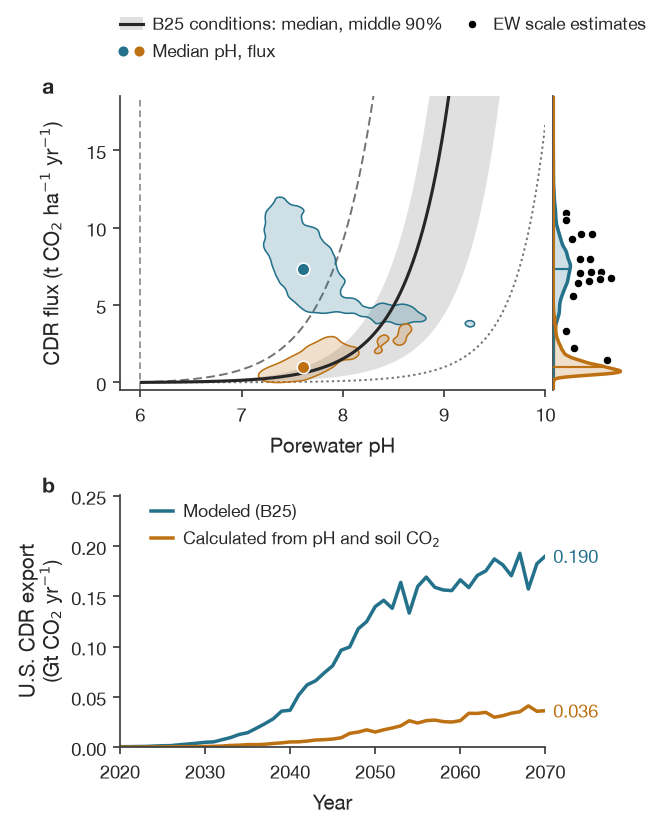

In [5]:
from scipy.ndimage import gaussian_filter

LEVELS = ((.9, .13), (.5, .30))     # cloud contours: (share of hectare-years inside, fill alpha), outermost first


def cloud(ax, f, color, z=2, levels=LEVELS):
    """Area-weighted point-years of (15 cm pH, flux `f`): the densest share at each of `levels`, from a
    smoothed 2-D histogram."""
    x, y, w = (a.transpose("point", "time").values.ravel() for a in (pt.pH_base.where(ACT), f, AREA))
    m = np.isfinite(x) & np.isfinite(y) & np.isfinite(w)
    H, xe, ye = np.histogram2d(x[m], y[m], bins=(np.arange(5, 10.001, .02), np.linspace(-1, 17, 220)),
                               weights=w[m])
    H = gaussian_filter(H, 2.5)
    h = np.sort(H.ravel())[::-1]
    lev = [h[np.searchsorted(np.cumsum(h) / h.sum(), p)] for p, _ in levels]
    X, Y = .5 * (xe[1:] + xe[:-1]), .5 * (ye[1:] + ye[:-1])
    for l, (_, a) in zip(lev, levels):
        ax.contourf(X, Y, H.T, levels=[l, H.max() * 2], colors=[color], alpha=a, zorder=z)
    ax.contour(X, Y, H.T, levels=sorted(lev), colors=[color], linewidths=.8, zorder=z)


def density_y(ax, x, w, color, *, lo, hi, n=400, fill=.22, z=3):
    """`density` on its side: flux runs up y, density out along x. Returns the KDE."""
    k = gaussian_kde(x, weights=w)
    ys = np.linspace(lo, hi, n)
    ax.fill_betweenx(ys, 0, k(ys), color=color, alpha=fill, lw=0, zorder=z)
    ax.plot(k(ys), ys, color=color, lw=1.8, zorder=z + 1)
    return k


def letter(ax, L):
    ax.annotate(L, xy=(0, 1), xycoords="axes fraction", xytext=(-40, 12),
                textcoords="offset points", fontweight="bold", fontsize=11, va="top", ha="left")


PH_LIM, YLIM = (5.8, 10), (-.5, HI)


def stack(v, gap=.45):
    """A row for each of the values `v`: values closer than `gap` take different rows, the lowest free first."""
    o, lvl = np.argsort(v), np.zeros(len(v), int)
    for j, i in enumerate(o):
        near = {lvl[k] for k in o[:j] if v[i] - v[k] < gap}
        lvl[i] = min(set(range(len(v))) - near)
    return lvl


def density_side(mx):
    """Side panel: the two flux distributions with their medians, and the EW scale estimates beside them."""
    kde = []
    for x, w, m, c, z in ((fx0, wf0, m0, C["e0"], 3), (fx2, wf2, m2, C["e2"], 5)):
        kde.append(k := density_y(mx, x, w, c, lo=LO, hi=HI, z=z))
        mx.hlines(m, 0, k(m)[0], color=c, lw=1.1, zorder=6)
    mx.set_xlim(0, mx.get_xlim()[1] * 1.45)
    # EW scale estimates just outside the distributions; dots closer than a dot's height step out
    iv = np.array([m["value"] for m in IAM.values()])
    iv = iv[(iv > YLIM[0]) & (iv < YLIM[1])]            # the dots are unclipped, so drop the off-axis ones
    lvl = stack(iv)
    edge = np.array([max(k(np.linspace(v - .3, v + .3, 13)).max() for k in kde) for v in iv])
    for L in range(lvl.max() + 1):
        step = mpl.transforms.ScaledTranslation((5 + 5.5 * L) / 72, 0, mx.figure.dpi_scale_trans)
        mx.plot(edge[lvl == L], iv[lvl == L], "o", ms=4.5, color="black", mec="white", mew=.6, ls="",
                transform=mx.transData + step, zorder=8, clip_on=False)
    mx.set_xlabel("density", color=C["muted"], fontsize=8.5)


def panel_a(ax, mx, ncol=3, ctrl="no-rock pH", fill=.07, links=True, levels=LEVELS, labels=True,
            side=None):
    """CDR vs pH from the carbonate system alone, B25's point-years over it; `mx` is the side panel
    (`side(mx)`, default `density_side`)."""
    xs = np.linspace(*PH_LIM, 400)
    lo_, mid, hi_ = (np.where((f := chem_flux(xs, cc, qq, PHC)) > 0, f, np.nan) for qq, cc in zip(QS, CO2S))
    if fill:
        ax.fill_between(xs, lo_, hi_, color=C["ink"], alpha=fill, lw=0, zorder=1)
    ax.plot(xs, hi_, color=C["muted"], lw=1.0, ls=(0, (4.5, 2.2)), zorder=2, label="wet, high CO$_2$")
    ax.plot(xs, mid, color=C["ink"], lw=1.6, zorder=3, label="median q, CO$_2$")
    ax.plot(xs, lo_, color=C["muted"], lw=1.0, ls=(0, (1.2, 1.6)), zorder=2, label="dry, low CO$_2$")
    ax.axvline(PHC, color=C["ctrl"], lw=1.0, ls=(0, (3.4, 2.0)), zorder=1)     # no-rock pH
    if labels:
        ax.annotate(f"{ctrl}\n{PHC:.2f}" + (f" ({PH_CTRL})" if isinstance(PH_CTRL, str) else ""),
                    xy=(PHC, 1), xycoords=("data", "axes fraction"), xytext=(4, -2), textcoords="offset points",
                    ha="left", va="top", fontsize=8, color=C["muted"], linespacing=1.15)
    cloud(ax, fy0, C["e0"], levels=levels)
    cloud(ax, fy2, C["e2"], levels=levels)
    for m, c in ((m0, C["e0"]), (m2, C["e2"])):
        if links:
            ax.hlines(m, PHM, PH_LIM[1], color=c, lw=.9, ls=(0, (1.2, 1.6)), zorder=2)
        ax.plot(PHM, m, "o", ms=6.5, mfc=c, mec="white", mew=.8, zorder=6)
        if labels:
            ax.annotate(f"{m:.1f}", xy=(PHM, m), xytext=(-6, 0), textcoords="offset points", color=c,
                        ha="right", va="center", zorder=7,
                        bbox=dict(boxstyle="round,pad=.12", fc="white", ec="none", alpha=.8))
    ax.set_xlim(PH_LIM); ax.set_ylim(YLIM)
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(1))
    ax.set_xlabel("Porewater pH at 15 cm")
    ax.set_ylabel("CDR flux (t CO$_2$ ha$^{-1}$ yr$^{-1}$)")
    # legend above the panel (the clouds fill the upper left)
    marks = [mpl.lines.Line2D([], [], ls="", marker="o", ms=6, mfc=C["muted"], mec="white", label="Median pH, flux"),
             *(mpl.patches.Patch(color=C["muted"], alpha=a, lw=0, label=f"{p} of point-years")
               for a, p in ((.43, "50%"), (.13, "90%"))),
             mpl.lines.Line2D([], [], ls="", marker="o", ms=4.5, mfc="black", mec="white", mew=.6,
                              label="EW scale estimates")]
    ax.legend(handles=ax.get_legend_handles_labels()[0] + marks, loc="lower left", bbox_to_anchor=(0, 1.03),
              ncol=ncol, fontsize=8, borderaxespad=0, columnspacing=1.0)

    # -- beside the panel, on its flux axis
    (side or density_side)(mx)
    mx.set_ylim(YLIM)
    mx.set_xticks([])
    mx.tick_params(axis="y", length=0, labelleft=False)
    mx.spines["bottom"].set_visible(False)
    letter(ax, "a")


def panel_b(bx, legend_size=None):
    """The national credited total, export only. `legend_size` sets the legend font."""
    for r, c, lab in ((r0, C["e0"], "Modeled (B25)"),
                      (r2, C["e2"], "Calculated from pH and soil CO$_2$")):
        bx.plot(YRS, r, color=c, lw=1.8, label=lab)
        bx.annotate(f"{r[-1]:.3f}", xy=(YRS[-1], r[-1]), xytext=(4, 0),
                    textcoords="offset points", color=c, fontsize=9.5, va="center")
    bx.set_xlim(2020, 2070); bx.set_ylim(0, max(r0.max(), r2.max()) * 1.30)
    bx.set_xlabel("Year")
    bx.set_ylabel("U.S. CDR export\n(Gt CO$_2$ yr$^{-1}$)")
    bx.legend(loc="upper left", bbox_to_anchor=(.06, 1), borderaxespad=.3, fontsize=legend_size)
    letter(bx, "b")


# -- the figure
ALKALINE = 7.5              # lower bound of the "alkaline soils" bar
CLOUD_75 = ((.75, .25),)    # one contour per cloud: the densest 75% of hectare-years

pt["qco2_base"] = pt.q * pt.soil_co2_base           # at a given pH the curves scale with q x soil CO2


def context_figure(b_height=1.8, levels=CLOUD_75, bare=False, side=None, side_width=.24, legend_size=None):
    """Panel a (2.1 in tall) over panel b (`b_height` in), end-members labelled and the alkaline strip on top.
    `bare` drops panel a's labels and the strip, keeping its room; `side_width` is a share of panel a's width."""
    a_height, gap, margin = 2.1, .75, (.67, .62)                # in; margins above and below
    h = a_height + gap + b_height + sum(margin)
    fig = plt.figure(figsize=(.7 * W["col2"] * (1 + side_width) / 1.24, h))     # panel a keeps its width
    rows = fig.add_gridspec(2, 1, height_ratios=(a_height, b_height), hspace=gap / ((a_height + b_height) / 2),
                            top=1 - margin[0] / h, bottom=margin[1] / h)
    top, bottom = (rows[i].subgridspec(1, 2, width_ratios=(1, side_width), wspace=.03) for i in (0, 1))
    ax, mx, bx = fig.add_subplot(top[0]), fig.add_subplot(top[1]), fig.add_subplot(bottom[0])
    panel_a(ax, mx, ctrl="Initial pH", fill=0, links=False, levels=levels, labels=not bare,
            side=side)
    panel_b(bx, legend_size)
    ax.set_xlabel("Porewater pH")
    mx.set_xlabel("")
    fig.align_ylabels((ax, bx))
    if bare:
        return fig, ax
    xs = np.linspace(*PH_LIM, 400)
    for i, y, name in ((2, .87 * HI, "wet"), (0, .73 * HI, "dry")):
        x = np.interp(y, chem_flux(xs, CO2S[i], QS[i], PHC), xs)           # where the end-member reaches y
        ax.annotate(f"{name}\n{QS[i]:g} m yr$^{{-1}}$\n{CO2S[i]:,.0f} ppm", xy=(x, y),
                    xytext=(-4, 0), textcoords="offset points", ha="right", va="center", fontsize=7.5,
                    color=C["muted"], linespacing=1.1)
    # the alkaline side, in a strip above the panel
    sx = ax.inset_axes([0, 1.015, 1, .07], sharex=ax)
    sx.axvspan(ALKALINE, PH_LIM[1], color="0.72", lw=0)
    sx.text(ALKALINE + .08, .5, f"Alkaline soils (>{ALKALINE})", transform=sx.get_xaxis_transform(),
            va="center", fontsize=8, color=C["ink"])
    sx.axis("off")
    return fig, ax


def relegend(ax, handles, labels, ncol=3, fontsize=8, colored=False):
    """Panel a's legend above the strip: `handles`, then the median dots (in E0's and E2's colours if
    `colored`) and EW scale estimates."""
    leg = ax.get_legend()
    kept = [(h, t.get_text()) for h, t in zip(leg.legend_handles, leg.texts)
            if t.get_text() in ("Median pH, flux", "EW scale estimates")]
    pair = tuple(mpl.lines.Line2D([], [], ls="", marker="o", ms=6, mfc=C[e], mec="white", mew=.8) for e in ("e0", "e2"))
    if colored:
        kept[0] = (pair, kept[0][1])
    ax.legend(handles=handles + [h for h, _ in kept], labels=labels + [l for _, l in kept], loc="lower left",
              bbox_to_anchor=(0, 1.12), ncol=ncol, fontsize=fontsize, borderaxespad=0, columnspacing=1.0,
              handler_map={pair: mpl.legend_handler.HandlerTuple(ndivide=None, pad=.5)})


def b25_band(ax, **legend):
    """B25's middle 90% in q x CO2 at the median q, one legend entry with the median curve."""
    xs = np.linspace(*PH_LIM, 400)
    ax.fill_between(xs, *(chem_flux(xs, wq(*flat("qco2_base"), p) / QS[1], QS[1], PHC) for p in (.05, .95)),
                    color=C["ink"], alpha=.14, lw=0, zorder=1)
    relegend(ax, [(mpl.patches.Patch(color=C["ink"], alpha=.14, lw=0), mpl.lines.Line2D([], [], color=C["ink"], lw=1.6))],
             ["B25 conditions: median, middle 90%"], **legend)


def ew_box(mx):
    """Side panel alternative: the EW scale estimates as a box and whiskers, each a dot over it."""
    v = np.array([m["value"] for m in IAM.values()])
    line = dict(color=C["muted"], lw=.8)
    mx.boxplot(v, positions=[.5], widths=.5, showfliers=False, patch_artist=True, zorder=2,
               boxprops=dict(facecolor=mpl.colors.to_rgba(C["ink"], .08), edgecolor=C["muted"], lw=.8),
               whiskerprops=line, capprops=line, medianprops=dict(color=C["ink"], lw=1.4))
    iv = v[(v > YLIM[0]) & (v < YLIM[1])]                         # the dots are unclipped
    lvl = stack(iv)
    slot = (lvl + 1) // 2 * np.where(lvl % 2, 1, -1)               # 0, +1, -1, +2, ...
    for s in np.unique(slot):
        step = mpl.transforms.ScaledTranslation(5.5 * s / 72, 0, mx.figure.dpi_scale_trans)
        mx.plot(np.full((slot == s).sum(), .5), iv[slot == s], "o", ms=4.5, color="black", mec="white", mew=.6,
                ls="", transform=mx.transData + step, zorder=8, clip_on=False)
    mx.set_xlim(0, 1)
    mx.spines["left"].set_visible(False)
    q1, med, q3 = np.percentile(v, (25, 50, 75))
    print(f"EW scale estimates (n = {len(v)}, {len(v) - len(iv)} above the axis): quartiles {q1:.2f}, "
          f"median {med:.2f}, {q3:.2f} t CO2/ha/yr")


# Panel a bare (labels and alkaline strip added offline, printed below), clouds at their densest 90%.
# `BOX`: the EW scale estimates as a box and whiskers instead of the flux distributions.
LEGEND_SIZE = 9
BOX = False
fig, ax = context_figure(levels=((.9, .22),), bare=True, legend_size=LEGEND_SIZE,
                         **(dict(side=ew_box, side_width=.14) if BOX else {}))
b25_band(ax, ncol=2, fontsize=LEGEND_SIZE, colored=True)
save(fig, "cdr_" + CASE)
for i, name in ((2, "wet, high CO2"), (0, "dry, low CO2")):
    print(f"{name:15s}" + "   ".join(f"pH {p:g}: {chem_flux(p, CO2S[i], QS[i], PHC):.2f}"
                              for p in (6.5, 7, 7.5, 8)) + "  t CO2/ha/yr")
print("Left off panel a, to add offline:")
for label, where in ((f"Initial pH {PHC:.2f}", "the dashed vertical line"),
                     (f"wet: {QS[2]:g} m yr⁻¹, {CO2S[2]:,.0f} ppm", "the dashed curve"),
                     (f"dry: {QS[0]:g} m yr⁻¹, {CO2S[0]:,.0f} ppm", "the dotted curve"),
                     (f"{m0:.1f}", f"the E0 (modeled) median dot, at pH {PHM:.2f}"),
                     (f"{m2:.1f}", f"the E2 (calculated) median dot, at pH {PHM:.2f}"),
                     (f"Alkaline soils (>{ALKALINE})", f"the strip above the panel, pH {ALKALINE}–{PH_LIM[1]:g}")):
    print(f"  {label:32s}{where}")

## Supplement — CDR fluxes and rates under two definitions

Solid: export (credited). Dashed: export + soil carbonate (SIC).

share of the raised alkalinity that is exported, ratio of medians
  E0  7.33 / 9.21 = 80%
  E2  0.99 / 2.94 = 34%
national, Gt CO2        2070 export  2070 exp+SIC   cum export  cum exp+SIC   share
  E0                  0.1901        0.2365         4.44         5.58      80%
  E2                  0.0362        0.0826         0.72         1.86      38%


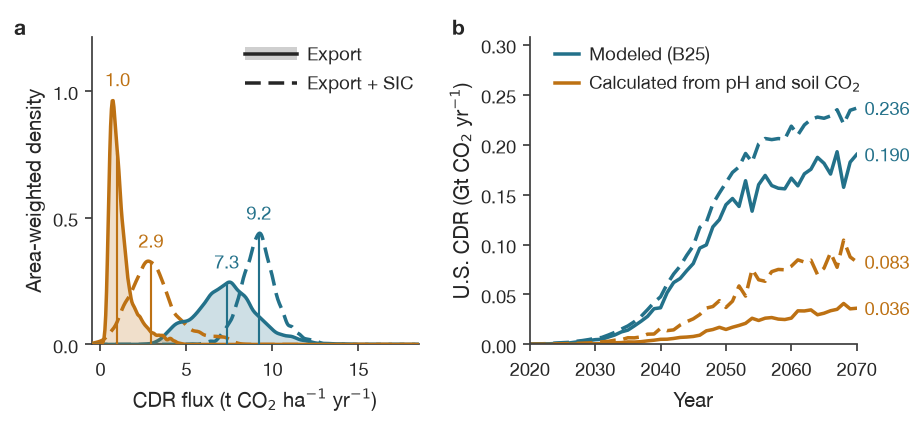

In [6]:
print(f"share of the raised alkalinity that is exported, ratio of medians")
print(f"  E0  {m0:.2f} / {s0:.2f} = {m0 / s0:.0%}")
print(f"  E2  {m2:.2f} / {s2:.2f} = {m2 / s2:.0%}")
n0, n2 = national("cdr"), national("cdr_e2")          # export + SIC, national rate
ct0 = (pt.cdr_total.fillna(0.).sum("point") / 1e9).values[-1]
ct2 = (pt.cdr_total_e2.fillna(0.).sum("point") / 1e9).values[-1]
print(f"national, Gt CO2        2070 export  2070 exp+SIC   cum export  cum exp+SIC   share")
print(f"  E0  {r0[-1]:22.4f} {n0[-1]:13.4f} {c0[-1]:12.2f} {ct0:12.2f} {c0[-1] / ct0:8.0%}")
print(f"  E2  {r2[-1]:22.4f} {n2[-1]:13.4f} {c2[-1]:12.2f} {ct2:12.2f} {c2[-1] / ct2:8.0%}")

DASH = (0, (4.5, 2.2))
SER = [(C["e0"], fx0, wf0, m0, sx0, ws0, s0, r0, n0, "Modeled (B25)", 3),
       (C["e2"], fx2, wf2, m2, sx2, ws2, s2, r2, n2, "Calculated from pH and soil CO$_2$", 5)]

fig, axes = plt.subplots(1, 2, figsize=(W["col2"], 2.85))
fig.subplots_adjust(wspace=.34)

# -- a: the flux distributions under both definitions --------------------------
ax = axes[0]
for c, fx, wf, _, sx, ws, _, _, _, _, z in SER:
    density(ax, fx, wf, c, lo=LO, hi=HI, log=False, z=z)
    density(ax, sx, ws, c, lo=LO, hi=HI, log=False, fill=0, ls=DASH, z=2)
ax.set_xlim(LO, HI)
ax.set_ylim(0, ax.get_ylim()[1] * 1.20)
for c, fx, wf, m, sx, ws, s, *_ in SER:
    inner(ax, fx, wf, m, c, f"{m:.1f}", log=False)
    inner(ax, sx, ws, s, c, f"{s:.1f}", log=False)
# neutral handles: colour is the experiment, line style the definition
kind = [(mpl.patches.Patch(color=C["ink"], alpha=.22, lw=0),
         mpl.lines.Line2D([], [], color=C["ink"], lw=1.8)),
        mpl.lines.Line2D([], [], color=C["ink"], lw=1.8, ls=DASH)]
ax.legend(kind, ["Export", "Export + SIC"], loc="upper right", borderaxespad=.3,
          handlelength=2.8)
ax.set_ylabel("Area-weighted density")
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
ax.set_xlabel("CDR flux (t CO$_2$ ha$^{-1}$ yr$^{-1}$)")

# -- b: the national trajectory under both definitions -------------------------
ax = axes[1]
for c, *_, r, n, lab, _ in SER:
    ax.plot(YRS, r, color=c, lw=1.8, label=lab)
    ax.plot(YRS, n, color=c, lw=1.8, ls=DASH)
    for y in (r, n):
        ax.annotate(f"{y[-1]:.3f}", xy=(YRS[-1], y[-1]), xytext=(4, 0),
                    textcoords="offset points", color=c, fontsize=9.5, va="center")
ax.set_xlim(2020, 2070); ax.set_ylim(0, max(n0.max(), n2.max()) * 1.30)
ax.set_xlabel("Year")
ax.set_ylabel("U.S. CDR (Gt CO$_2$ yr$^{-1}$)")
ax.legend(loc="upper left", bbox_to_anchor=(.06, 1), borderaxespad=.3)

for ax, L in zip(axes, "ab"):
    ax.annotate(L, xy=(0, 1), xycoords="axes fraction", xytext=(-40, 12),
                textcoords="offset points", fontweight="bold", fontsize=11,
                va="top", ha="left")

save(fig, "cdr-definitions_" + CASE)

## Supplement — water flux through the column, `q`

Filled: every deployed point-year. Dashed: each point's mean over its deployed years.

q, m/yr       min   p5  median  p95   max
  point-years   0.16  0.44   0.83  1.17  1.87
  point means   0.23  0.41   0.82  1.02  1.34


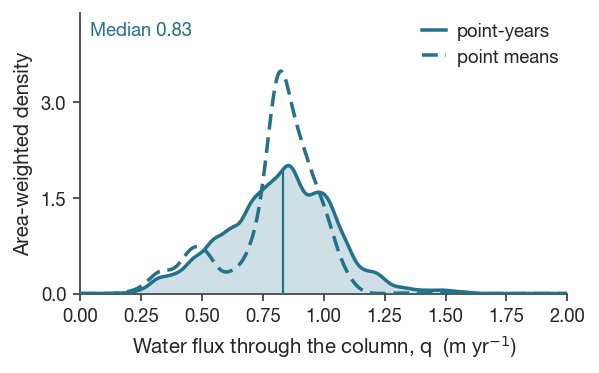

In [13]:
qy, qw = flat("q")
qp = pt.q.where(ACT).mean("time").values
qa = pt.area_ha.values[np.isfinite(qp)]
qp = qp[np.isfinite(qp)]
mq = wq(qy, qw, .5)
print(f"q, m/yr       min   p5  median  p95   max")
for k, x, w in (("point-years", qy, qw), ("point means", qp, qa)):
    print(f"  {k}  {x.min():5.2f} {wq(x, w, .05):5.2f} {wq(x, w, .5):6.2f} {wq(x, w, .95):5.2f} {x.max():5.2f}")

fig, ax = plt.subplots(figsize=(W["col15"], 2.6))
density(ax, qy, qw, C["e0"], "point-years", lo=0, hi=2, log=False)
density(ax, qp, qa, C["e0"], "point means", lo=0, hi=2, log=False, fill=0, ls=DASH, z=2)
ax.set_xlim(0, 2)
ax.set_ylim(0, ax.get_ylim()[1] * 1.20)
inner(ax, qy, qw, mq, C["e0"], "", log=False)          # unlabelled: the point-means peak sits there
ax.annotate(f"Median {mq:.2f}", xy=(.02, .97), xycoords="axes fraction", color=C["e0"], va="top")
ax.set_xlabel("Water flux through the column, q  (m yr$^{-1}$)")
ax.set_ylabel("Area-weighted density")
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(3))
ax.legend(loc="upper right")

save(fig, "q-dist_" + CASE)